In [36]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250324/all_rRNA_prediction/test/river_internal_test/without_structure_feature_detection")
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
import seaborn as sns
import pandas as pd
from scipy.stats import mannwhitneyu

In [30]:
matrix = np.zeros((1020,1020))
with open("28S_rRNA_merge_RICseq_KR_5.matrix","r")as f:
    for line in f:
        if "chrom1" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(int(sub[0])/5)
            right = int(int(sub[1])/5)
            value = float(sub[2])

            if left < right:
                matrix[left,right] = value

In [31]:
raw_const = set()
with open("raw_structure1.bedpe","r")as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                raw_const.add((left,right))

wd_const = set()
with open("wd_structure1.bedpe","r")as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                wd_const.add((left,right))

In [32]:
raw_support = []
for pair in raw_const:
    raw_support.append(matrix[int(pair[0]/5),int(pair[1]/5)])

wd_support = []
for pair in wd_const:
    wd_support.append(matrix[int(pair[0]/5),int(pair[1]/5)])

In [34]:
print(np.median(raw_support),np.median(wd_support))

658.5409 620.9467


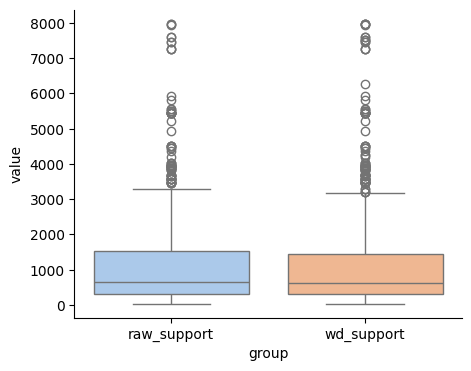

In [ ]:
fig, axs = plt.subplots(1, figsize=(5, 4))

all_data = [raw_support,wd_support]

labels = ['raw_support','wd_support']

df = pd.DataFrame({
    'value': np.concatenate(all_data),
    'group': np.repeat(labels, [len(data) for data in all_data])
})

ax = sns.boxplot(x='group', y='value', data=df, hue='group', legend=False,palette="pastel") #, cut=0 ,showfliers=False

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig("const_support.pdf", format="pdf", bbox_inches="tight")

In [ ]:
all_data = [raw_support, wd_support]

group_names = ['raw_support', 'wd_support']

def perform_targeted_comparisons(data_list, names, alpha=0.05):
    comparisons = [
        (0, 1, 'f_values vs nf_values') 
    ]
    
    results = []
    
    print("=" * 70)
    print("n:")
    for i, name in enumerate(names):
        print(f"{name}: n = {len(data_list[i])}")
    
    print("=" * 70)
    print("result:")
    print("=" * 70)
    
    for idx1, idx2, comp_name in comparisons:
        data1 = data_list[idx1]
        data2 = data_list[idx2]
        n1 = len(data1)
        n2 = len(data2)
        
        stat, p_val = mannwhitneyu(data1, data2, alternative='two-sided')
        
        effect_r = 1 - (2 * stat) / (n1 * n2)
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        mean1 = np.mean(data1)
        mean2 = np.mean(data2)
        iqr1 = np.percentile(data1, 75) - np.percentile(data1, 25)
        iqr2 = np.percentile(data2, 75) - np.percentile(data2, 25)
        
        n_boot = 1000
        boot_diffs = []
        for _ in range(n_boot):
            sample1 = np.random.choice(data1, size=len(data1), replace=True)
            sample2 = np.random.choice(data2, size=len(data2), replace=True)
            boot_diffs.append(np.median(sample1) - np.median(sample2))
        
        ci_low = np.percentile(boot_diffs, 2.5)
        ci_high = np.percentile(boot_diffs, 97.5)
        
        results.append({
            'Comparison': comp_name,
            'U_Statistic': stat,
            'P_Value': p_val,
            'Effect_Size_r': effect_r,
            'n1': n1,
            'n2': n2,
            'Median1': median1,
            'Median2': median2,
            'Median_Diff': median1 - median2,
            'Median_Diff_CI': f"[{ci_low:.3f}, {ci_high:.3f}]",
            'Mean1': mean1,
            'Mean2': mean2,
            'IQR1': iqr1,
            'IQR2': iqr2,
            'Significant': p_val < alpha
        })
        
        print(f"{comp_name}: U = {stat:.0f}, p = {p_val:.3e}, r = {effect_r:.3f}")
        print(f"  n: {names[idx1]}={n1}, {names[idx2]}={n2}")
        print(f"  median: {names[idx1]}={median1:.3f}, {names[idx2]}={median2:.3f}")
        print(f"  median_diff: {median1 - median2:.3f} (95% CI: [{ci_low:.3f}, {ci_high:.3f}])")
        print(f"  r: |r| = {abs(effect_r):.3f}")
    
    results_df = pd.DataFrame(results)
    
    results_df['Sig_Marker'] = results_df['P_Value'].apply(
        lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    )
    
    print("\n" + "=" * 70)
    print("summary:")
    print("=" * 70)
    
    return results_df

alpha = 0.05
results_df = perform_targeted_comparisons(all_data, group_names, alpha=alpha)

print("\ntable:")
print("=" * 70)
print(results_df.to_string(index=False))

print("\n (α = 0.05):")
print("=" * 70)
for _, row in results_df.iterrows():
    print(f"{row['Comparison']}: {row['Sig_Marker']} (p = {row['P_Value']:.3e})")

print("=" * 70)
for _, row in results_df.iterrows():
    effect_size = abs(row['Effect_Size_r'])
    print(f"{row['Comparison']}: |r| = {effect_size:.3f}")